# AP 155 Lab Exercise
---
## Exercise 13: Ordinary differential equations

_Instructions_:
- **Report Figure:** Generate two figures: (1) famous Lorenz butterfly $x-z$ plot and (2) Van-der-Pol oscillator phase space plot
- **Report Discussion:** Explain the dynamics in the figures. Discuss how Euler's method and RK4 work in a nutshell. Distinguish the advantages and disadvantages between Euler vs RK4.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name_: Joaquin A. Castaneda
- _Student No._: 2024-09743
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness  | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figure

![exe13_fig1.png](exe13_fig1.png)

Figure 1. The famous Lorenz butterfly $x-z$ plot

![exe13_fig2.png](exe13_fig2.png)

Figure 2. Van-der-Pol oscillator phase space plot

### Report discussion

**Dynamics in the figures.** For Figure 1, the path circles one lobe for a few loops, and then it then jumps to the other lobe, and it keeps switching in an irregular pattern without ever repeating or settling. There is no randomness in the equations, hence, this irregular motion is deterministic chaos. As for figure 2, every curve starts at (1, 0) and then quickly settles into a closed loop that keeps repeating. A larger mu stretches the loop, and the velocity gets higher (about 6 at μ = 4).

**Euler and RK4.** Euler's method takes the slope at the current point and steps straight forward by h. RK4 also steps forward, however, it checks the slope four times within each step and uses a weighted average of them.

**Euler vs RK4.** Euler is simple and cheap per step, however, it is inaccurate and needs a very small h. RK4 is much more accurate for the same h, but it is harder to code and costs four function calculations per step.

### Other comments
- Figure 1 is so cool. 

---
## Section 2: Code

In [8]:
import matplotlib.pyplot as plt
import numpy as np

import seaborn as sns # Guide: https://seaborn.pydata.org/tutorial/introduction.html
sns.set_theme(style="darkgrid")

rng = np.random.default_rng()

### Exercise 1: Simultaneous 1st order ODEs

One of the most celebrated sets of differential equations in physics is the Lorenz equations
\begin{align}
\frac{dx}{dt} &= \sigma(y-x) \\
\frac{dy}{dt} &= \rho x - y - xz\\
\frac{dz}{dt} &= xy - \beta z \\
\end{align}
where $\mu$, $\rho$, and $\beta$ are constants. (The names $\mu$, $\rho$, and $\beta$ are odd, but traditional --- they
are always used in these equations for historical reasons.)

These equations were first studied by Edward Lorenz in 1963, who derived them from a simplified model of weather patterns. The reason for their fame is that they were one of the first incontrovertible examples of *deterministic chaos*, the occurrence of apparently random motion even though there is no randomness built into the equations. We encountered a different example of chaos in the logistic map.

**(a)** Write a program to solve the Lorenz equations for the case $\sigma = 10$, $\rho = 28$, and $\beta =\frac{8}{3}$ in the range from $t = 0$ to $t = 50$ with initial conditions $(x,y,z) =(0, 1,0)$. Plot the trajectory $(x(t), y(t), z(t))$ for different parameter values. One trajectory should clearly illustrate the chaotic behavior of the Lorenz attractor.

Hint: you may use `euler()` or `rk4()` in Section 3.

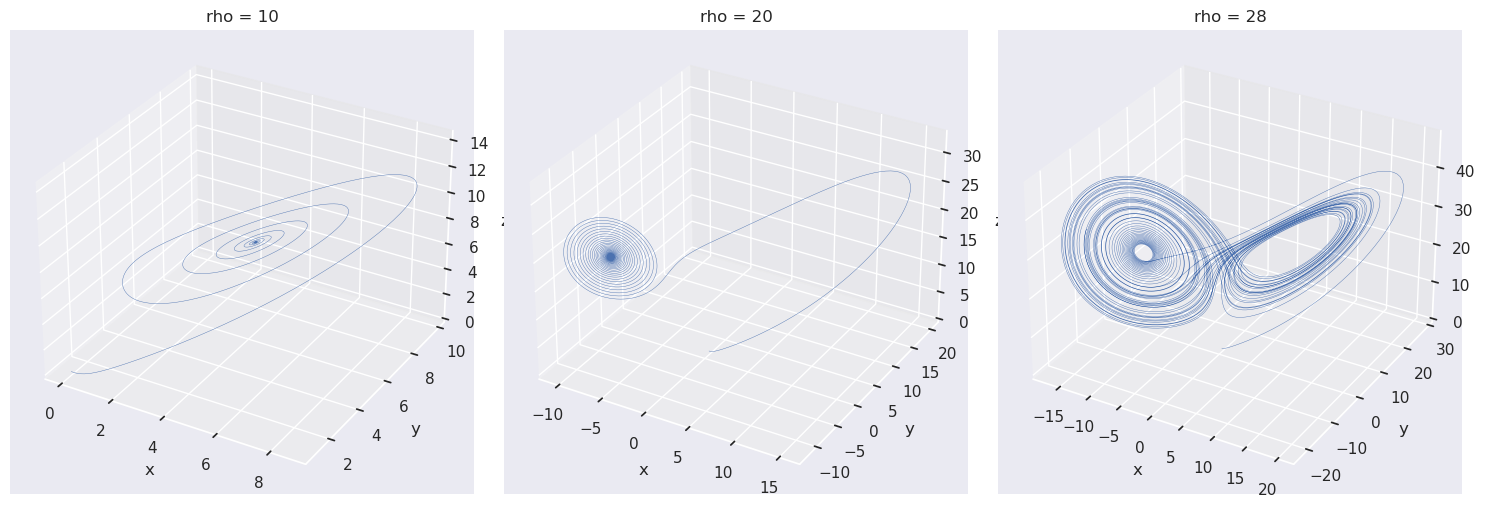

In [9]:
# RK4 solver for systems of ODEs
def rk4_vec(f, a, b, n, yinit):
    h = (b - a)/(n - 1)                 # ung step size
    ts = a + np.arange(n)*h             # ung time values
    ys = np.zeros((n, len(yinit)))      # storage for solutions
    y = np.array(yinit, dtype=float)    # initial conditions

    for j, t in enumerate(ts):
        ys[j] = y                      # i-store current values

        # RK4 steps
        k0 = h*f(t, y)
        k1 = h*f(t + h/2, y + k0/2)
        k2 = h*f(t + h/2, y + k1/2)
        k3 = h*f(t + h, y + k2)

        y = y + (k0 + 2*k1 + 2*k2 + k3)/6  # i-update solution

    return ts, ys

# Lorenz equations
sigma, beta = 10, 8/3

def lorenz(t, r, rho):
    x, y, z = r                     # extract sina x, y, z
    return np.array([
        sigma*(y - x),
        rho*x - y - x*z,
        x*y - beta*z
    ])

# Solve and plot for different rho values
a, b, n = 0, 50, 10000              # time range and number of steps
yinit = [0, 1, 0]                   # initial conditions
rhos = [10, 20, 28]                 # values of rho to compare

fig = plt.figure(figsize=(15, 5))

for i, rho in enumerate(rhos):
    # solve the system for each rho
    ts, sol = rk4_vec(
        lambda t, r: lorenz(t, r, rho),
        a, b, n, yinit
    )

    # plot the 3D trajectory
    ax = fig.add_subplot(1, 3, i+1, projection="3d")
    ax.plot(sol[:, 0], sol[:, 1], sol[:, 2], lw=0.3)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("z")
    ax.set_title(f"rho = {rho}")

plt.tight_layout()
plt.show()

**(b)** Modify your program to produce a plot of $z$ against $x$. You should see a picture of the famous "strange attractor" of the Lorenz equations, a lop-sided butterfly-shaped plot that never repeats itself.

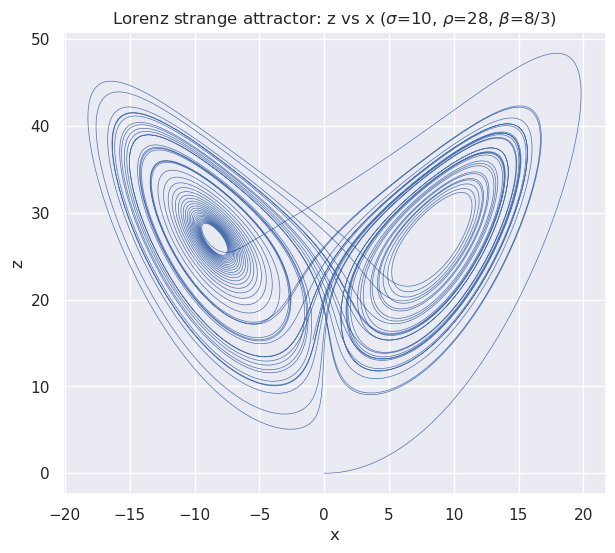

In [10]:
# same thing as (a) at rho = 28 pero only plot z vs x. bumped n up para the curve looks smooth
ts, sol = rk4_vec(lambda t, r: lorenz(t, r, 28), 0, 50, 25000, [0, 1, 0])

plt.figure(figsize=(7, 6))
plt.plot(sol[:, 0], sol[:, 2], lw=0.5)
plt.xlabel("x")
plt.ylabel("z")
plt.title(r"Lorenz strange attractor: z vs x ($\sigma$=10, $\rho$=28, $\beta$=8/3)")
plt.savefig('exe13_fig1.png', dpi=300)
plt.show()

### Exercise 2: Second-order ODEs (Harmonic and anharmonic oscillators)

The simple harmonic oscillator arises in many physical problems, in mechanics, electricity and magnetism, and condensed matter physics, among other areas. Consider the standard oscillator equation
$$ \frac{d^2x}{dt^2} = - \omega^2 x $$.

**(a)** Turn this second-order equation into two coupled first-order equations. Then write a program to solve them for the case $\omega = 1$ in the range from $t=0$ to $t= 50$. A second-order equation requires two initial conditions, one on $x$ and one on its derivative. For this problem use $x = 1$ and $\frac{dx}{dt} = 0$ as initial conditions. Have your program
make a graph showing the value of $x$ as a function of time.

$$ \frac{dx}{dt} = y$$
$$ \frac{dy}{dt} = - \omega^2 x $$

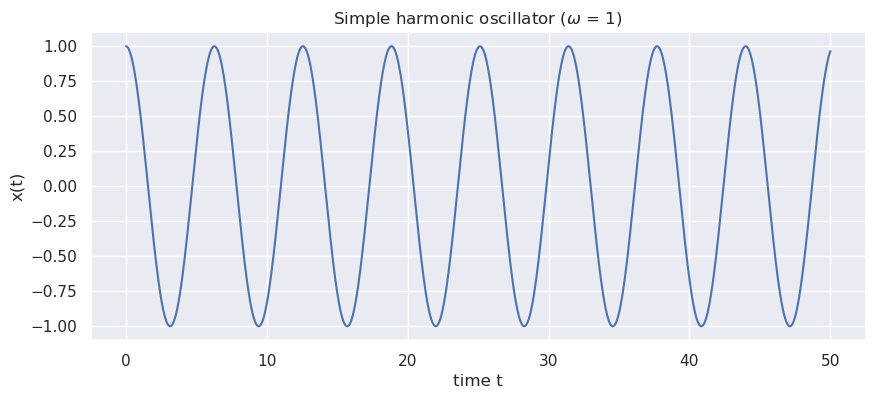

In [11]:
# SHM: convert ung 2nd-order ODE into 2 coupled 1st-order ODEs
# y = [x, v], wherein, v = dx/dt

def sho(t, y, omega=1):
    x, v = y
    return np.array([v, -omega**2 * x])

# i-solve gamit RK4
a, b, n = 0, 50, 5001          # time range and number of steps
ts, sol = rk4_vec(sho, a, b, n, [1, 0])  # initial conditions: x=1, v=0

# Plot x wrt t
plt.figure(figsize=(10, 4))
plt.plot(ts, sol[:, 0])
plt.xlabel("time t")
plt.ylabel("x(t)")
plt.title(r"Simple harmonic oscillator ($\omega$ = 1)")
plt.show()

**(b)** Now increase the amplitude of the oscillations by making the initial value of $x$ bigger --- say $x = 2$ --- and confirm that the period of the oscillations stays roughly the same.

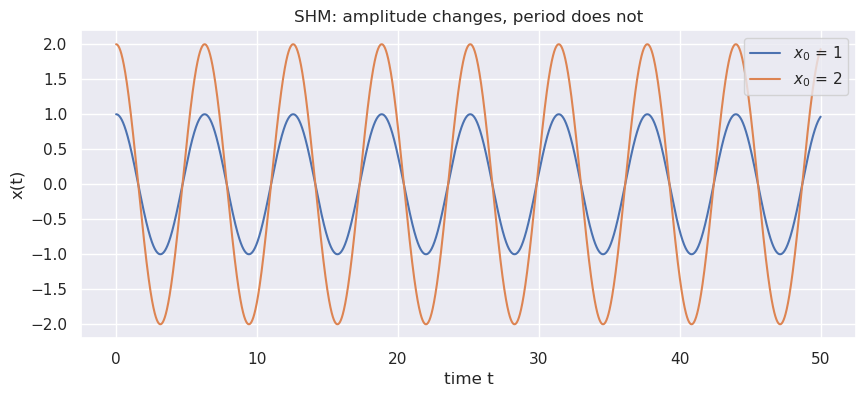

In [15]:
# SHM (b): compare x0 = 1 and x0 = 2
# Reuses sho() and rk4_vec() from (a)

ts, s1 = rk4_vec(sho, 0, 50, 5001, [1, 0])   # x0 = 1
ts, s2 = rk4_vec(sho, 0, 50, 5001, [2, 0])   # x0 = 2

plt.figure(figsize=(10, 4))
plt.plot(ts, s1[:, 0], label=r"$x_0$ = 1")
plt.plot(ts, s2[:, 0], label=r"$x_0$ = 2")
plt.xlabel("time t")
plt.ylabel("x(t)")
plt.title("SHM: amplitude changes, period does not")
plt.legend()
plt.show()

**(c)** Modify your program to solve for the motion of the anharmonic oscillator described by the equation
$$ \frac{d^2 x}{dt} = -\omega^2 x^3.$$

Again take $\omega= 1$ and initial conditions $x = 1$ and $dx/dt = 0$ and make a plot of the motion of the oscillator. Again increase the amplitude. You should observe that the oscillator oscillates faster at higher amplitudes. (You can try lower amplitudes too if you like, which should be slower.)

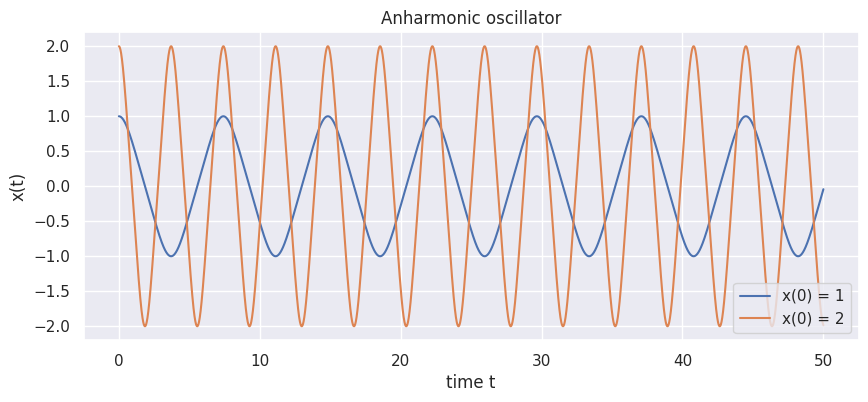

In [6]:
# Anharmonic oscillator: y = [x, v]
def aho(t, y, omega=1):
    x, v = y
    return np.array([v, -omega**2 * x**3])


# Solve for different initial amplitudes
a, b, n = 0, 50, 5001
amplitudes = [1, 2]

plt.figure(figsize=(10, 4))

for A in amplitudes:
    ts, sol = rk4_vec(aho, a, b, n, [A, 0])
    plt.plot(ts, sol[:, 0], label=f"x(0) = {A}")

plt.xlabel("time t")
plt.ylabel("x(t)")
plt.title("Anharmonic oscillator")
plt.legend()
plt.show()

**(d)** Modify your program so that instead of plotting $x$ against $t$, it plots $\frac{dx}{dt}$ against $x$, i.e., the "velocity" of the oscillator against its "position." Such a plot is called a *phase space* plot.

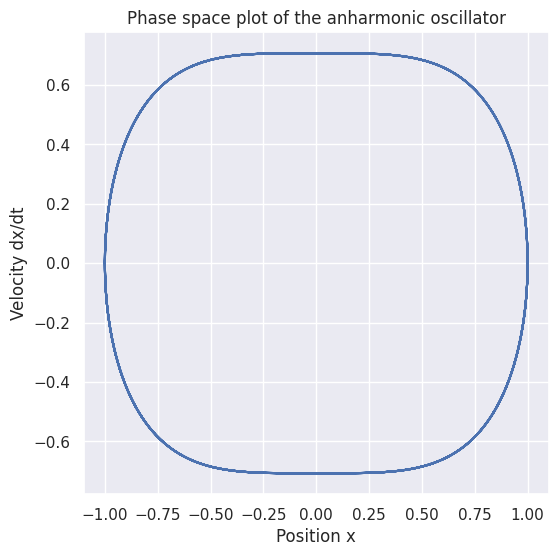

In [7]:
# Solve ung anharmonic oscillator
ts, sol = rk4_vec(aho, 0, 50, 5001, [1, 0])

# Plot velocity against position (phase space)
plt.figure(figsize=(6, 6))
plt.plot(sol[:, 0], sol[:, 1])
plt.xlabel("Position x")
plt.ylabel("Velocity dx/dt")
plt.title("Phase space plot of the anharmonic oscillator")
plt.show()

**(e)** The van der Pol oscillator, which appears in electronic circuits and in laser physics, is described by the equation
$$\frac{d^2x }{dt^2} - \mu(1-x^2)\frac{dx}{dt} + x = 0 $$
Use the same techniques as the one above (i.e. rewrite into 2 1st-order ODEs). Modify your program to solve this equation from $t=0$ to $t=20$ and hence make a phase space plot for the van der Pol oscillator with $\omega=1$, $\mu = 1$, and initial conditions $x = 1$ and $dx/dt = 0$. Try it also for $\mu=2$ and $\mu=4$ (still with $\omega = 1$). Make sure you use a small enough value of the time interval $h$ to get a smooth, accurate phase space plot.

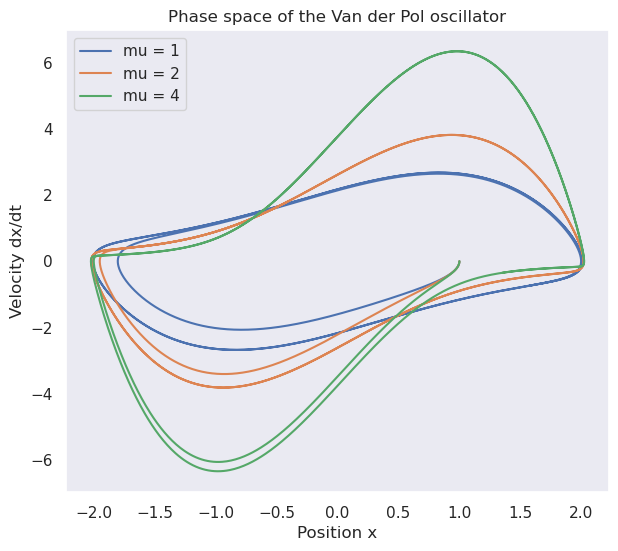

In [6]:
# Van der Pol oscillator: y = [x, v]
def vdp(t, y, mu=1, omega=1):
    x, v = y
    return np.array([
        v,
        mu*(1 - x**2)*v - omega**2*x
    ])

# Solve and plot for different mu values
a, b, n = 0, 20, 10001       # h = 0.002
yinit = [1, 0]                # initial conditions
mus = [1, 2, 4]

plt.figure(figsize=(7, 6))

for mu in mus:
    ts, sol = rk4_vec(
        lambda t, y: vdp(t, y, mu),
        a, b, n, yinit
    )

    # Plot velocity against position
    plt.plot(sol[:, 0], sol[:, 1], label=f"mu = {mu}")

plt.xlabel("Position x")
plt.ylabel("Velocity dx/dt")
plt.title("Phase space of the Van der Pol oscillator")
plt.legend()
plt.grid()
plt.savefig('exe13_fig2.png', dpi=300)
plt.show()

#### Problem code summary

Exercise 1: Lorenz Equations

The Lorenz equations were solved numerically using the RK4 method with the given initial conditions and parameters. Different values of rho were tested in order to compare the system's behavior, whilst the x-z plot at rho = 28 illustrates the characteristic butterfly-shaped strange attractor and chaotic behavior.

Exercise 2: Harmonic and Anharmonic Oscillators

The second-order equations were rewritten as pairs of first-order equations and solved with RK4. For the harmonic oscillator, a bigger starting amplitude did not change the period, whereas, for the anharmonic oscillator, a bigger amplitude made it oscillate faster. The phase space plot of the anharmonic oscillator is a closed loop, whilst, the van der Pol oscillator settles into a repeating loop that gets more stretched as mu increases.

---
## Section 3: Notes

In [ ]:
import numpy as np

# Ricatti equation (mildly nonlinear)
def f(x,y):
    return - (30/(1-x**2)) + ((2*x)/(1-x**2))*y - y**2

### IVPs

#### 1st order ODE solver: Euler's method

In [ ]:
# forward Euler's method
def euler(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        y += h*f(x, y)
    return xs, ys

#### 1st order ODE solver: Rungke-Kutta method

In [ ]:
# 4th order Runge-Kutta method
def rk4(f,a,b,n,yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros(n)
    y = yinit
    for j,x in enumerate(xs):
        ys[j] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

In [ ]:
# execution
a, b, n, yinit = 0.05, 0.49, 12, 19.53
xs, ys = euler(f,a,b,n,yinit); print(ys)
xs, ys = rk4(f,a,b,n,yinit); print(ys)

[ 19.53         3.14847227   1.56501191   0.26296871  -0.97182666
  -2.28204589  -3.81903888  -5.80936521  -8.6780744  -13.37838499
 -22.50759395 -45.29198435]
[ 19.53        10.16782416   6.37032643   4.11921483   2.48829431
   1.12081032  -0.17770512  -1.56533384  -3.24322678  -5.58940124
  -9.6041146  -19.50349262]


#### 2nd-order ODE: RK4

In [ ]:
def fs(x,yvals):
    y0, y1 = yvals
    f0 = y1
    f1 = - (30/(1-x**2))*y0 + ((2*x)/(1-x**2))*y1
    return np.array([f0, f1])

def rk4gen(fs,a,b,n,yinits):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals)
        k1 = h*fs(x+h/2, yvals+k0/2)
        k2 = h*fs(x+h/2, yvals+k1/2)
        k3 = h*fs(x+h, yvals+k2)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

a, b, n = 0.05, 0.49, 12
yinits = np.array([0.0926587109375, 1.80962109375])
xs, ys = rk4gen(fs,a,b,n,yinits)
print(ys)

[[ 0.09265871  1.80962109]
 [ 0.16241651  1.66496084]
 [ 0.22481633  1.44262901]
 [ 0.27687631  1.1492782 ]
 [ 0.3159291   0.79398005]
 [ 0.33971857  0.38822519]
 [ 0.34649662 -0.05407672]
 [ 0.33511993 -0.51659705]
 [ 0.3051467  -0.98058819]
 [ 0.25693343 -1.42488364]
 [ 0.19173167 -1.82589807]
 [ 0.1117848  -2.15762739]]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Updated to handle arrays (systems of ODEs)
def euler(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit))) # Modified to hold vector outputs
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        y += h*f(x, y)
    return xs, ys

def rk4(f, a, b, n, yinit):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, len(yinit))) # Modified to hold vector outputs
    y = np.array(yinit, dtype=float)
    for j, x in enumerate(xs):
        ys[j, :] = y
        k0 = h*f(x, y)
        k1 = h*f(x+h/2, y+k0/2)
        k2 = h*f(x+h/2, y+k1/2)
        k3 = h*f(x+h, y+k2)
        y += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

#### Shooting methods

In [ ]:
def secant(f,x0,x1,kmax=200,tol=1.e-8):
    f0 = f(x0)
    for k in range(1,kmax):
        f1 = f(x1)
        ratio = (x1 - x0)/(f1 - f0)
        x2 = x1 - f1*ratio
        xdiff = abs(x2-x1)
        x0, x1 = x1, x2
        f0 = f1
        rowf = "{0:2d}{1:1.16f} {2:1.16f} {3:1.16f}"
        print(rowf.format(k,x2,xdiff,abs(f(x2))))
        if abs(xdiff/x2) < tol:
            break
    else:
        x2 = None

    return x2

def shoot(sig):
    a, b, n = 0.05, 0.49, 100
    yinits = np.array([0.0926587109375, sig])
    xs, ys = rk4gen(fs,a,b,n,yinits)
    wfinal = 0.11177050858750004
    return ys[-1, 0] - wfinal

wder = secant(shoot,0.,1.)
print(wder)

 11.8096210699240751 0.8096210699240751 0.0000000000000001
 21.8096210699240738 0.0000000000000013 0.0000000000000001
1.8096210699240738


#### BVP matrix

In [ ]:
from gauelimpivot import gauelimpivot
import numpy as np

def matsetup(a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    A = np.zeros((n,n))
    np.filldiagonal(A, -2 + 30*h**2/(1-xs**2))
    A[0,0] = 1; A[-1,-1] = 1
    np.filldiagonal(A[1:,:], 1 + h*xs[1:]/(1-xs[1:]**2))
    A[-1,-2] = 0
    np.filldiagonal(A[:,1:], 1 - h*xs/(1-xs**2))
    A[0,1] = 0
    bs = np.zeros(n)
    bs[0] = 0.0926587109375
    bs[-1] = 0.11177050858750004
    return A, bs

def riccati(a,b,n):
    A, bs = matsetup(a, b, n)
    ws = gauelimpivot(A, bs)
    return ws

a, b, n = 0.05, 0.49, 400
ws = riccati(a, b, n); print(ws)

ModuleNotFoundError: No module named 'gauelimpivot'

#### Shooting method

In [ ]:
from secant import secant
import numpy as np

def fs(x,yvals,s):
    q = 1.5
    y0, y1 = yvals
    f0 = y1
    f1 = (2*q*np.cos(2*x) - s)*y0
    return np.array([f0, f1])

def rk4geneig(fs,a,b,n,yinits,s):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    ys = np.zeros((n, yinits.size))
    yvals = np.copy(yinits)
    for j,x in enumerate(xs):
        ys[j,:] = yvals
        k0 = h*fs(x, yvals,s)
        k1 = h*fs(x+h/2, yvals+k0/2,s)
        k2 = h*fs(x+h/2, yvals+k1/2,s)
        k3 = h*fs(x+h, yvals+k2,s)
        yvals += (k0 + 2*k1 + 2*k2 + k3)/6
    return xs, ys

def shoot(s):
    a, b, n = 0, 2*np.pi, 500
    yinits = np.array([0., 5.])
    xs, ys = rk4geneig(fs,a,b,n,yinits,s)
    wfinal = 0.
    return ys[-1, 0] - wfinal

for sinit in (-0.4, 3.3, 8.5):
    sval = secant(shoot,sinit,sinit+0.5)
    print(sval, end=" ")

ModuleNotFoundError: No module named 'secant'

#### Matrix approach

In [ ]:
from qrmet import qrmet
import numpy as np

def matsetup(q,n):
    h = 2*np.pi/n
    xs = np.arange(n)*h
    A = np.zeros((n,n))
    np.filldiagonal(A, -2 - 2*h**2*q*np.cos(2*xs))
    np.filldiagonal(A[1:,:], 1)
    np.filldiagonal(A[:,1:], 1)
    A[0,-1] = 1
    A[-1,0] = 1
    return A

def mathieu(q,n):
    A = matsetup(q, n)
    qreigvals = qrmet(A,200)
    h = 2*np.pi/n
    qreigvals = np.sort(-qreigvals/h**2)
    return qreigvals

q, n = 1.5, 200
qreigvals = mathieu(q, n)
print(qreigvals[:6])

ModuleNotFoundError: No module named 'qrmet'

### Plotting

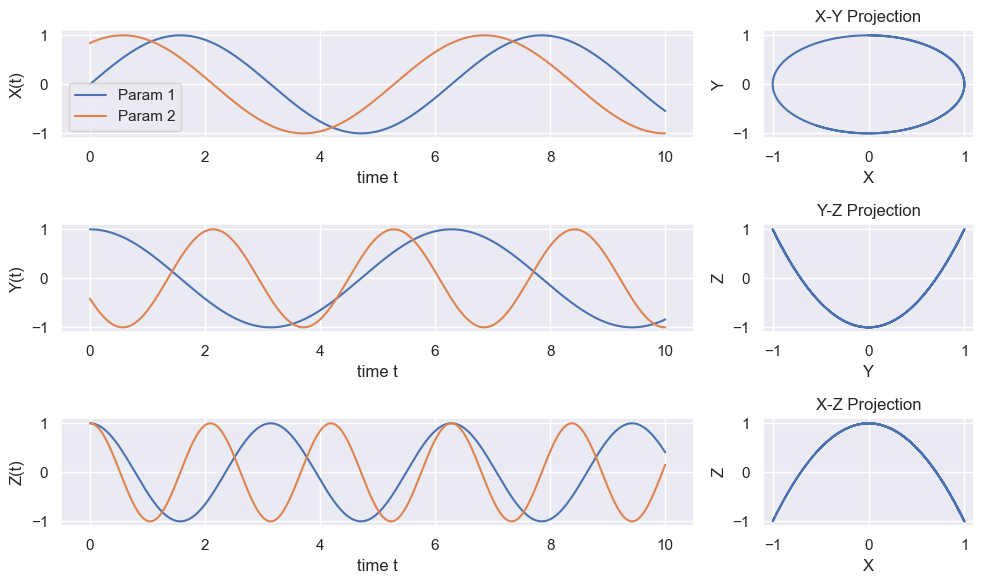

In [ ]:
# SAMPLE DATA ONLY
t = np.linspace(0, 10, 1000)
x = np.sin(t)
y = np.cos(t)
z = np.cos(2*t)

x1 = np.sin(t + 1)
y1 = np.cos(2*t + 2)
z1 = np.cos(3*t)


# See: https://stackoverflow.com/questions/10388462/matplotlib-different-size-subplots
fig, axs = plt.subplots(3, 2, figsize=(10, 6), gridspec_kw={'width_ratios': [3, 1]})

# Time series
axs[0, 0].plot(t, x, label="Param 1")
axs[0, 0].plot(t, x1, label="Param 2")
axs[0, 0].legend()
axs[0, 0].set_ylabel("X(t)")

axs[1, 0].plot(t, y)
axs[1, 0].plot(t, y1)
axs[1, 0].set_ylabel("Y(t)")

axs[2, 0].plot(t, z)
axs[2, 0].plot(t, z1)
axs[2, 0].set_ylabel("Z(t)")

# add xlabel to all time series
for ax in axs[:, 0]:
    ax.set_xlabel("time t")

# Phase plot
axs[0, 1].plot(x, y)
axs[0, 1].set(title="X-Y Projection", xlabel="X", ylabel="Y")

axs[1, 1].plot(y, z)
axs[1, 1].set(title="Y-Z Projection", xlabel="Y", ylabel="Z")

axs[2, 1].plot(x, z)
axs[2, 1].set(title="X-Z Projection", xlabel="X", ylabel="Z")

fig.tight_layout()

### Practice: Simple pendulum
$$\frac{d^2\theta}{dt^2}=-\frac{g}{l}\sin\theta $$

- Variables: ${\theta}$
- Parameters: ${g, l}$

To solve a second-order ODE, we reduce it to two first-order ODEs.
Let $\theta = y_0$ and $\omega = \frac{d\theta}{dt} = y_1$.
The system becomes:
\begin{align}
\frac{dy_0}{dt} &= y_1 \\
\frac{dy_1}{dt} &= -\frac{g}{l}\sin(y_0)
\end{align}

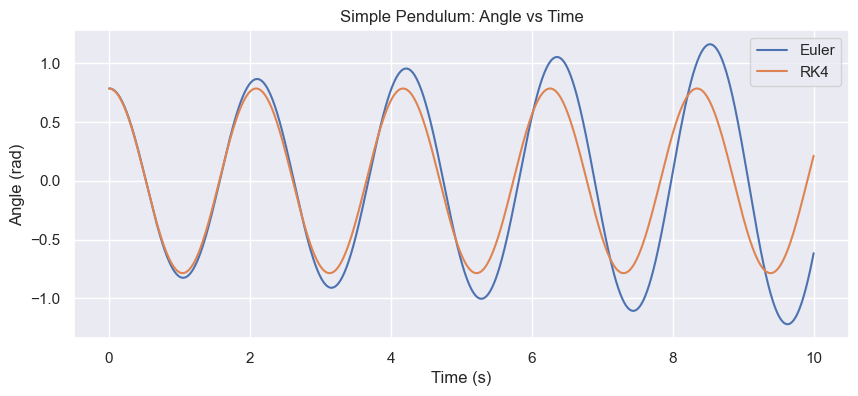

In [ ]:
def pendulum_ode(t, Y):
    g = 9.81
    l = 1.0
    theta, omega = Y
    return np.array([omega, -(g/l)*np.sin(theta)])

# init conds (arbitrary): pi/4 angle, 0 initial velocity
yinit = [np.pi/4, 0.0]
t, Y_euler = euler(pendulum_ode, 0, 10, 1000, yinit)
t, Y_rk4 = rk4(pendulum_ode, 0, 10, 1000, yinit)

plt.figure(figsize=(10,4))
plt.plot(t, Y_euler[:,0], label='Euler')
plt.plot(t, Y_rk4[:,0], label='RK4')
plt.title("Simple Pendulum: Angle vs Time")
plt.xlabel("Time (s)")
plt.ylabel("Angle (rad)")
plt.legend()
plt.show()

**End of Notebook.**